# Netflix Data Visualization Dashboard

**Task 4 — Data Visualization Dashboard | Stage 1: Python Data Visualization & Data Preparation for Power BI**

**Purpose** – Convert the raw Netflix catalogue data into clean datasets and decision-oriented charts, and prepare files for the Stage 2 Power BI dashboard.

**Dataset** – Netflix Movies and TV Shows (`netflix.csv`): 8,807 records, 12 columns (`show_id`, `type`, `title`, `director`, `cast`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in`, `description`).

**Objective** – Understand what the catalogue contains (Movies vs TV Shows, genres, countries, ratings), how it has grown over time, and export Power BI-ready data.

**Tools** – Python, Pandas, NumPy, Matplotlib, Seaborn.

**Notebook flow:** inspect → clean → engineer features → explode genres/countries → KPIs → charts → export → validate → insights.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

# Clean, minimal styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

NETFLIX_RED = "#B20710"
NEUTRAL = "#4C4C4C"
TYPE_PALETTE = {"Movie": NETFLIX_RED, "TV Show": NEUTRAL}

## 3. Create Required Directories

In [8]:
CHART_DIR = "E:/HorizonX/task4/visualisations"
PROCESSED_DIR = "E:/HorizonX/task4/processed"

os.makedirs(CHART_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
print("Directories ready:", CHART_DIR, "|", PROCESSED_DIR)

Directories ready: E:/HorizonX/task4/visualisations | E:/HorizonX/task4/processed


## 4. Load Dataset

In [9]:
df = pd.read_csv("E:/HorizonX/task4/netflix_titles.csv")

print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Shape: (8807, 12)

Column names: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


In [10]:
print("First 5 rows")
display(df.head())
print("Last 5 rows")
display(df.tail())

First 5 rows


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Last 5 rows


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## 5. Initial Data Understanding
Before changing anything, we check the size, types, missing values and duplicates.

In [12]:
# Concise data-quality summary
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]} | Exact duplicate rows: {df.duplicated().sum()}")
display(quality)

Rows: 8,807 | Columns: 12 | Exact duplicate rows: 0


,missing_count,missing_pct,unique_values
show_id,0,0.00,8807
type,0,0.00,2
title,0,0.00,8807
director,2634,29.91,4528
cast,825,9.37,7692
country,831,9.44,748
date_added,10,0.11,1767
release_year,0,0.00,74
rating,4,0.05,17
duration,3,0.03,220


In [13]:
# Statistical overview (only the compact columns, to keep output readable)
display(df.describe(include="all").loc[["count", "unique", "top", "freq", "mean", "min", "max"],
                                         ["type", "country", "release_year", "rating", "duration"]])

,type,country,release_year,rating,duration
count,8807,7976,8807.000000,8803,8804
unique,2,748,NaN,17,220
top,Movie,United States,NaN,TV-MA,1 Season
freq,6131,2818,NaN,3207,1793
mean,NaN,NaN,2014.180198,NaN,NaN
min,NaN,NaN,1925.000000,NaN,NaN
max,NaN,NaN,2021.000000,NaN,NaN


In [14]:
# Value-level check: are the categorical fields consistent?
print("Types:", df["type"].value_counts().to_dict())
print("\nRating values (all):")
print(df["rating"].value_counts(dropna=False).to_dict())

Types: {'Movie': 6131, 'TV Show': 2676}

Rating values (all):
{'TV-MA': 3207, 'TV-14': 2160, 'TV-PG': 863, 'R': 799, 'PG-13': 490, 'TV-Y7': 334, 'TV-Y': 307, 'PG': 287, 'TV-G': 220, 'NR': 80, 'G': 41, 'TV-Y7-FV': 6, nan: 4, 'NC-17': 3, 'UR': 3, '66 min': 1, '74 min': 1, '84 min': 1}


**Observation:** `director`, `cast` and `country` have many missing values; `date_added`, `rating` and `duration` have only a few.
In the `rating` list, some values such as `74 min`, `84 min`, `66 min` are *durations*, not ratings — the same rows have a missing `duration`. This looks like a column shift in the source data, so we repair it in the next step rather than dropping those rows.

## 6. Data Cleaning and Preprocessing

**Treatment plan (and why):**

| Column | Treatment | Reason |
|---|---|---|
| `director`, `cast`, `country` | Fill with `"Unknown"` | These are descriptive text fields; the title is still valid for other analyses, so we keep the row. |
| `rating` | Fill with `"Unknown"` (after fixing shifted values) | Categorical; zero or a guess would be misleading. |
| `duration` | Recover from shifted `rating` values; otherwise `"Unknown"` | The correct value is present in the wrong column. |
| `date_added` | `pd.to_datetime(errors="coerce")`, left as missing (`NaT`) if invalid | A date cannot be invented; yearly/monthly charts simply exclude those few rows. |
| Duplicates | Remove exact duplicates | Duplicate records would inflate counts. |

In [15]:
df = df.copy()

# Strip stray whitespace from text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].str.strip()

# --- Repair shifted values: duration stored inside the rating column ---
shifted = df["rating"].str.contains(r"\d+\s*min", case=False, na=False) & df["duration"].isna()
print("Rows where duration was stored in 'rating':", shifted.sum())
display(df.loc[shifted, ["title", "type", "rating", "duration"]])

df.loc[shifted, "duration"] = df.loc[shifted, "rating"]
df.loc[shifted, "rating"] = np.nan

Rows where duration was stored in 'rating': 3


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


In [16]:
# --- Missing values ---
print("Missing values BEFORE:")
print(df[["director", "cast", "country", "date_added", "rating", "duration"]].isna().sum())

for col in ["director", "cast", "country", "rating", "duration"]:
    df[col] = df[col].fillna("Unknown")

# date_added: convert to datetime; invalid / missing become NaT (not invented)
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

print("\nMissing values AFTER:")
print(df[["director", "cast", "country", "date_added", "rating", "duration"]].isna().sum())

Missing values BEFORE:
director      2634
cast           825
country        831
date_added      10
rating           7
duration         0
dtype: int64

Missing values AFTER:
director       0
cast           0
country        0
date_added    10
rating         0
duration       0
dtype: int64


In [17]:
# --- Duplicates ---
dup_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
dup_after = df.duplicated().sum()
print(f"Duplicates before: {dup_before} | after: {dup_after} | rows now: {len(df):,}")
print("Duplicate show_id values:", df["show_id"].duplicated().sum())

Duplicates before: 0 | after: 0 | rows now: 8,807
Duplicate show_id values: 0


## 7. Feature Engineering
New columns make the data easier to chart and filter in Power BI. Original `country` and `listed_in` are kept untouched.

In [18]:
# Date features (stay missing when date_added is missing)
df["year_added"] = df["date_added"].dt.year.astype("Int64")
df["month_added"] = df["date_added"].dt.month.astype("Int64")
df["month_name"] = df["date_added"].dt.month_name()

# Duration features: "90 min" -> 90 / Minutes ; "2 Seasons" -> 2 / Season
df["duration_value"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

def get_duration_unit(text):
    text = str(text).lower()
    if "min" in text:
        return "Minutes"
    if "season" in text:
        return "Season"
    return "Unknown"

df["duration_unit"] = df["duration"].apply(get_duration_unit)

# Primary genre / primary country = first value listed
df["primary_genre"] = df["listed_in"].str.split(",").str[0].str.strip()
df["country_primary"] = df["country"].str.split(",").str[0].str.strip()
df["country_primary"] = df["country_primary"].replace("", "Unknown")

display(df[["title", "type", "date_added", "year_added", "month_name", "duration",
            "duration_value", "duration_unit", "primary_genre", "country_primary"]].head(8))
print(df.groupby(["type", "duration_unit"]).size())

,title,type,date_added,year_added,month_name,duration,duration_value,duration_unit,primary_genre,country_primary
0,Dick Johnson Is Dead,Movie,2021-09-25,2021,September,90 min,90,Minutes,Documentaries,United States
1,Blood & Water,TV Show,2021-09-24,2021,September,2 Seasons,2,Season,International TV Shows,South Africa
2,Ganglands,TV Show,2021-09-24,2021,September,1 Season,1,Season,Crime TV Shows,Unknown
3,Jailbirds New Orleans,TV Show,2021-09-24,2021,September,1 Season,1,Season,Docuseries,Unknown
4,Kota Factory,TV Show,2021-09-24,2021,September,2 Seasons,2,Season,International TV Shows,India
5,Midnight Mass,TV Show,2021-09-24,2021,September,1 Season,1,Season,TV Dramas,Unknown
6,My Little Pony: A New Generation,Movie,2021-09-24,2021,September,91 min,91,Minutes,Children & Family Movies,Unknown
7,Sankofa,Movie,2021-09-24,2021,September,125 min,125,Minutes,Dramas,United States


type     duration_unit
Movie    Minutes          6131
TV Show  Season           2676
dtype: int64


## 8. Genre Processing
`listed_in` holds several genres per title (e.g. `Dramas, International Movies`). We split and explode so each genre gets its own row.

In [19]:
genre_df = df[["show_id", "title", "type", "listed_in"]].copy()
genre_df["genre"] = genre_df["listed_in"].str.split(",")
genre_df = genre_df.explode("genre")
genre_df["genre"] = genre_df["genre"].str.strip()
genre_df = genre_df[genre_df["genre"].notna() & (genre_df["genre"] != "")]
genre_df = genre_df.drop(columns="listed_in").reset_index(drop=True)

top_genres = genre_df["genre"].value_counts().head(10)
print(f"Titles: {len(df):,} -> genre records: {len(genre_df):,}")
display(genre_df.head())
display(top_genres.to_frame("titles"))

Titles: 8,807 -> genre records: 19,323


,show_id,title,type,genre
0,s1,Dick Johnson Is Dead,Movie,Documentaries
1,s2,Blood & Water,TV Show,International TV Shows
2,s2,Blood & Water,TV Show,TV Dramas
3,s2,Blood & Water,TV Show,TV Mysteries
4,s3,Ganglands,TV Show,Crime TV Shows


,titles
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


## 9. Country Processing
`country` can list several countries per title. Rows with no country are labelled `Unknown` in the data, but `Unknown` is **excluded from the Top-10 ranking** because it is not a country.

In [20]:
country_df = df[["show_id", "title", "type", "country"]].copy()
country_df["country"] = country_df["country"].str.split(",")
country_df = country_df.explode("country")
country_df["country"] = country_df["country"].str.strip()
country_df = country_df[country_df["country"].notna() & (country_df["country"] != "")]
country_df = country_df.reset_index(drop=True)

known_countries = country_df[country_df["country"] != "Unknown"]
top_countries = known_countries["country"].value_counts().head(10)
print(f"Titles: {len(df):,} -> country records: {len(country_df):,}")
display(top_countries.to_frame("titles"))

Titles: 8,807 -> country records: 10,843


,titles
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


## 10. KPI / Summary Statistics

In [21]:
movies = df[df["type"] == "Movie"]
tv_shows = df[df["type"] == "TV Show"]
movie_minutes = movies.loc[movies["duration_unit"] == "Minutes", "duration_value"].dropna()

kpis = {
    "Total titles": len(df),
    "Total movies": len(movies),
    "Total TV shows": len(tv_shows),
    "Unique countries (excl. Unknown)": known_countries["country"].nunique(),
    "Unique genres": genre_df["genre"].nunique(),
    "Earliest release year": int(df["release_year"].min()),
    "Latest release year": int(df["release_year"].max()),
    "Average release year": round(df["release_year"].mean(), 1),
}
movie_kpis = {
    "Average movie duration (min)": round(movie_minutes.mean(), 1),
    "Median movie duration (min)": movie_minutes.median(),
    "Minimum movie duration (min)": movie_minutes.min(),
    "Maximum movie duration (min)": movie_minutes.max(),
}
display(pd.Series({**kpis, **movie_kpis}, name="Value").to_frame())

,Value
Total titles,8807.0
Total movies,6131.0
Total TV shows,2676.0
Unique countries (excl. Unknown),122.0
Unique genres,42.0
Earliest release year,1925.0
Latest release year,2021.0
Average release year,2014.2
Average movie duration (min),99.6
Median movie duration (min),98.0


## Reusable Plot Helpers
Small functions avoid repeating the save/format code for every chart.

In [23]:
def save_chart(fig, filename):
    """Apply tight layout and save the figure as a 300-dpi PNG."""
    fig.tight_layout()
    path = os.path.join(CHART_DIR, filename)
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved:", path)

def horizontal_bar(series, title, xlabel, ylabel, filename, color=NETFLIX_RED):
    """Horizontal bar chart with the largest value at the top and value labels."""
    data = series.sort_values(ascending=True)  # barh plots first item at the bottom
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(data.index, data.values, color=color)
    for y, v in enumerate(data.values):
        ax.text(v + data.max() * 0.01, y, f"{v:,}", va="center", fontsize=9)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, data.max() * 1.12)
    save_chart(fig, filename)
    plt.show()

## 11. Visualization 1 — Movies vs TV Shows

,titles,share_%
type,,
Movie,6131,69.6
TV Show,2676,30.4


Saved: E:/HorizonX/task4/visualisations\01_movies_vs_tv_shows.png


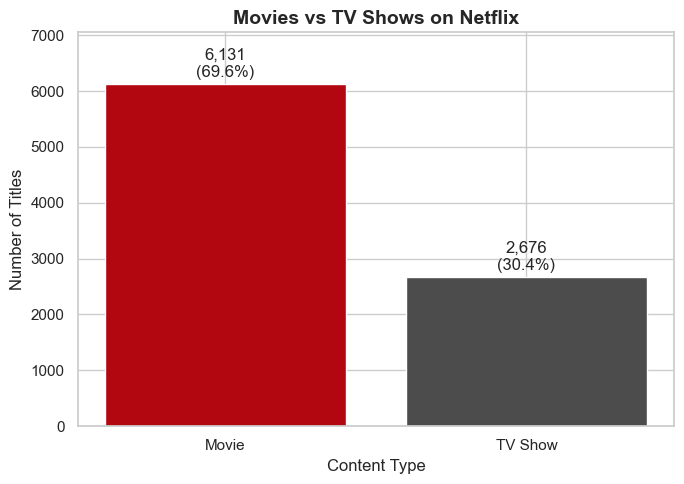

In [24]:
type_counts = df["type"].value_counts()
type_share = (type_counts / type_counts.sum() * 100).round(1)
display(pd.DataFrame({"titles": type_counts, "share_%": type_share}))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(type_counts.index, type_counts.values,
              color=[TYPE_PALETTE.get(t, NEUTRAL) for t in type_counts.index])
for bar, t in zip(bars, type_counts.index):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + type_counts.max() * 0.01,
            f"{type_counts[t]:,}\n({type_share[t]}%)", ha="center", va="bottom")
ax.set_title("Movies vs TV Shows on Netflix", fontsize=14)
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")
ax.set_ylim(0, type_counts.max() * 1.15)
save_chart(fig, "01_movies_vs_tv_shows.png")
plt.show()

## 12. Visualization 2 — Content Added Over Time

Titles with a valid date_added: 8797 of 8807
Saved: E:/HorizonX/task4/visualisations\02_content_added_over_time.png


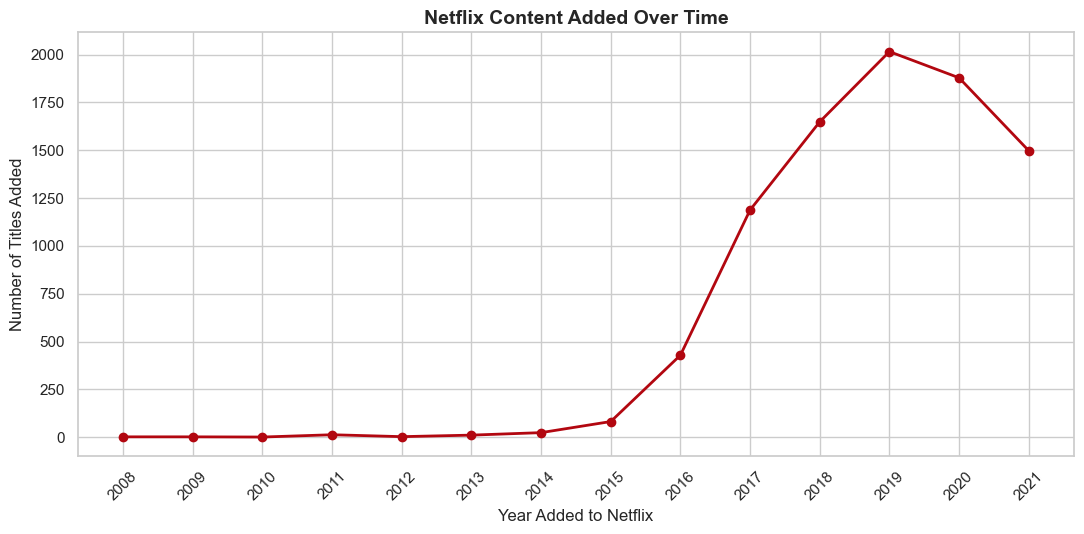

In [25]:
added_per_year = df["year_added"].dropna().astype(int).value_counts().sort_index()
print("Titles with a valid date_added:", int(added_per_year.sum()), "of", len(df))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(added_per_year.index, added_per_year.values, marker="o", color=NETFLIX_RED, linewidth=2)
ax.set_title("Netflix Content Added Over Time", fontsize=14)
ax.set_xlabel("Year Added to Netflix")
ax.set_ylabel("Number of Titles Added")
ax.set_xticks(added_per_year.index)
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "02_content_added_over_time.png")
plt.show()

*Note:* the last year in the data may be incomplete (the dataset is a snapshot), so a drop in the final year should not be read as a real decline without checking the latest `date_added`.

In [26]:
print("Latest date_added in dataset:", df["date_added"].max().date())

Latest date_added in dataset: 2021-09-25


## 13. Visualization 3 — Top 10 Countries

Saved: E:/HorizonX/task4/visualisations\03_top_10_countries.png


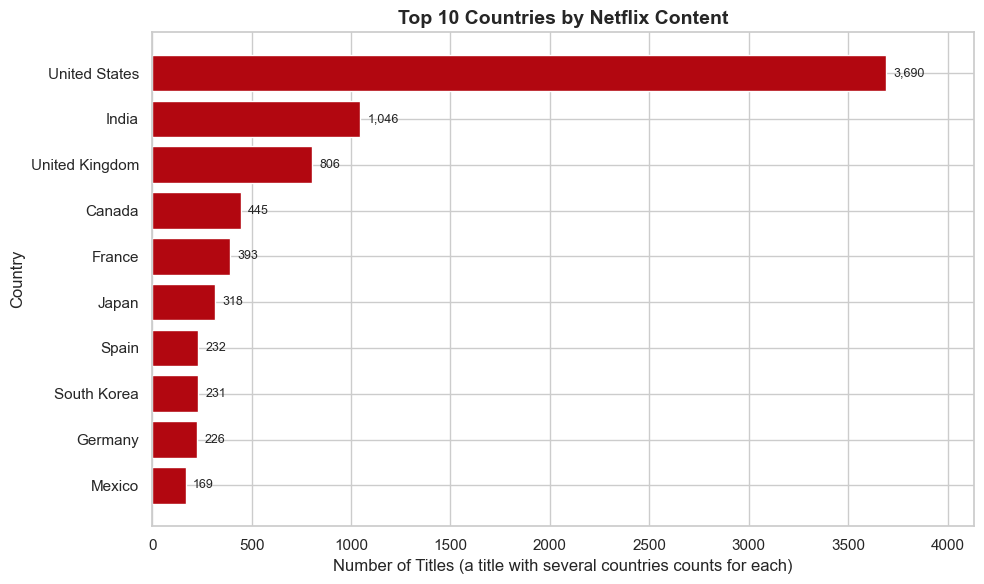

In [27]:
horizontal_bar(top_countries,
               title="Top 10 Countries by Netflix Content",
               xlabel="Number of Titles (a title with several countries counts for each)",
               ylabel="Country",
               filename="03_top_10_countries.png")

## 14. Visualization 4 — Top 10 Genres

Saved: E:/HorizonX/task4/visualisations\04_top_10_genres.png


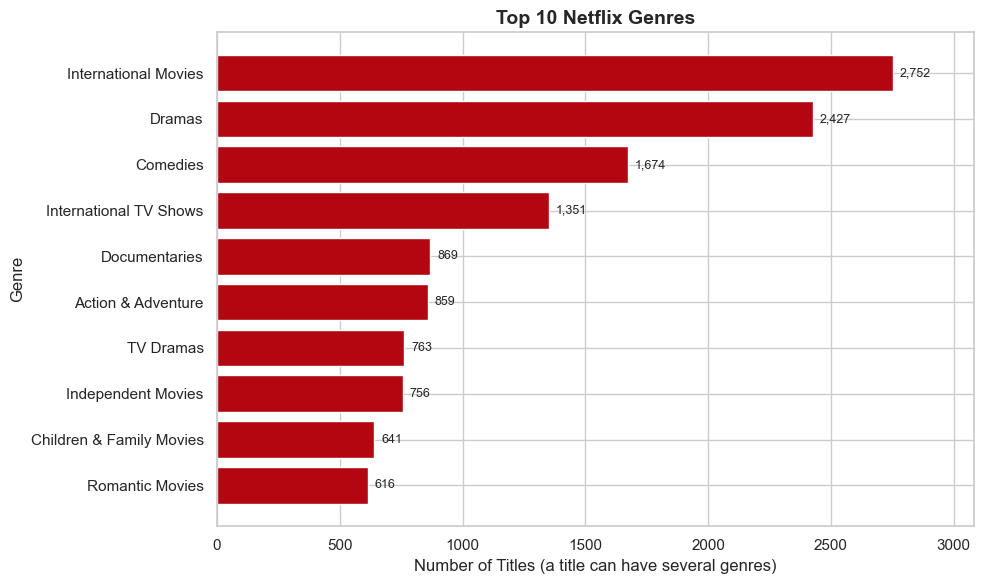

In [28]:
horizontal_bar(top_genres,
               title="Top 10 Netflix Genres",
               xlabel="Number of Titles (a title can have several genres)",
               ylabel="Genre",
               filename="04_top_10_genres.png")

## 15. Visualization 5 — Content Ratings

Saved: E:/HorizonX/task4/visualisations\05_content_ratings.png


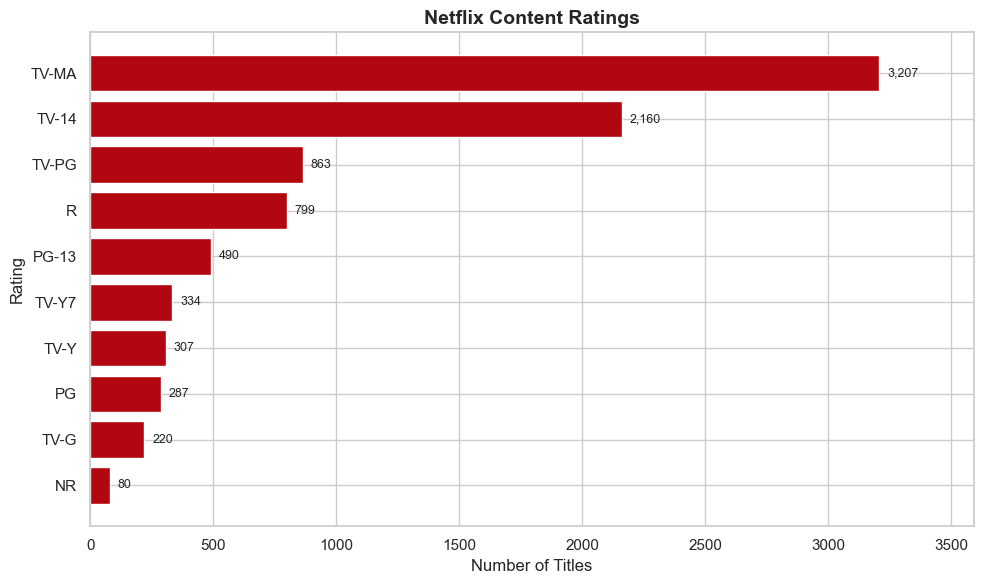

In [29]:
top_ratings = df["rating"].value_counts().head(10)
horizontal_bar(top_ratings,
               title="Netflix Content Ratings",
               xlabel="Number of Titles",
               ylabel="Rating",
               filename="05_content_ratings.png")

## 16. Visualization 6 — Release Year Distribution
Release years span many decades with a sharp concentration in recent years, so a **line chart of titles per release year** shows the pattern more clearly than wide histogram bins.

Saved: E:/HorizonX/task4/visualisations\06_release_year_distribution.png


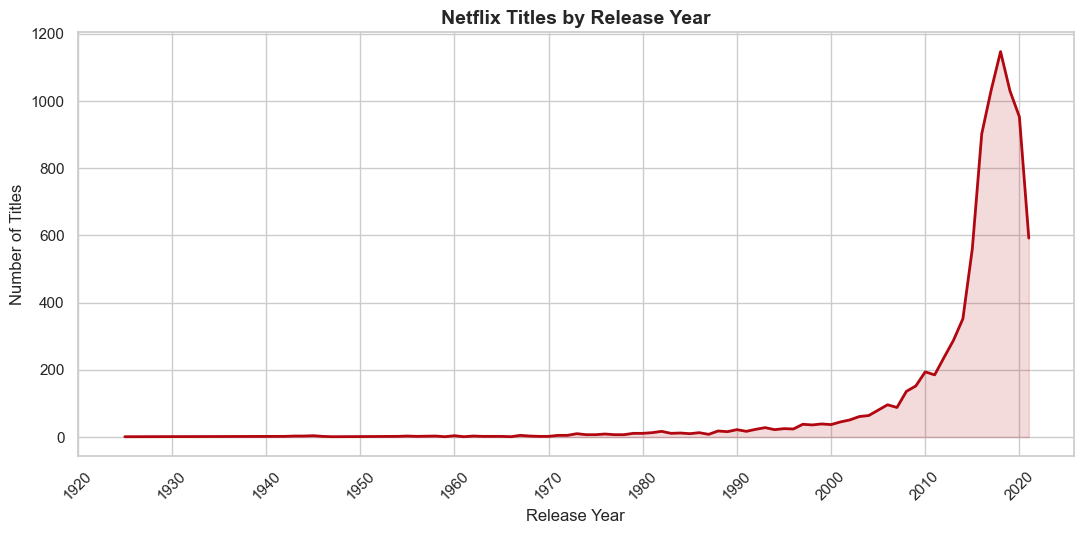

Share of titles released in 2015 or later: 70.6%


In [30]:
release_counts = df["release_year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(release_counts.index, release_counts.values, color=NETFLIX_RED, linewidth=2)
ax.fill_between(release_counts.index, release_counts.values, color=NETFLIX_RED, alpha=0.15)
ax.set_title("Netflix Titles by Release Year", fontsize=14)
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")
ax.set_xticks(range(int(release_counts.index.min()) // 10 * 10, int(release_counts.index.max()) + 1, 10))
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "06_release_year_distribution.png")
plt.show()

recent_share = (df["release_year"] >= 2015).mean() * 100
print(f"Share of titles released in 2015 or later: {recent_share:.1f}%")

## 17. Visualization 7 — Movie Duration Distribution

Movies used: 6,131
Saved: E:/HorizonX/task4/visualisations\07_movie_duration_distribution.png


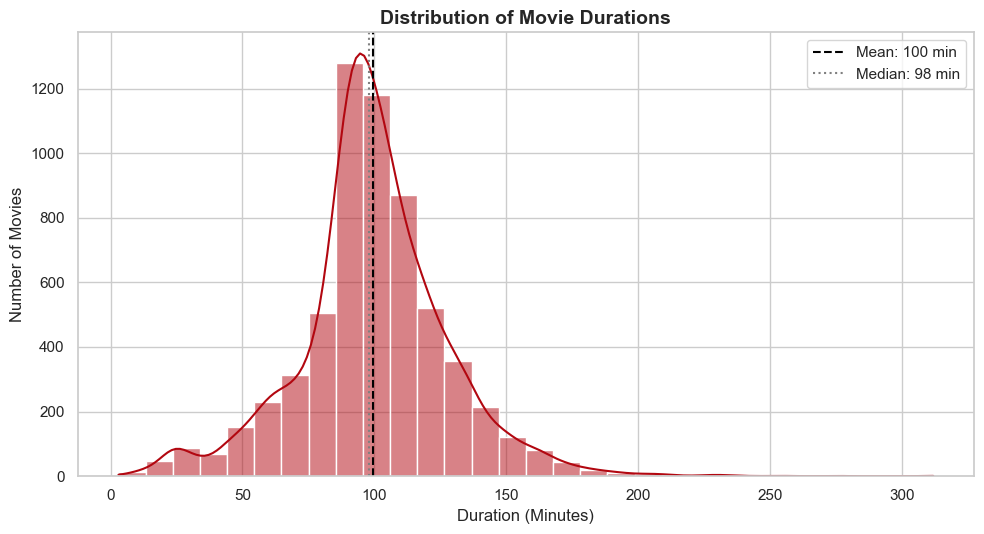

In [31]:
# Movies only, minutes only (season-based and unknown values excluded)
movie_dur = df[(df["type"] == "Movie") & (df["duration_unit"] == "Minutes")]["duration_value"].dropna()
print(f"Movies used: {len(movie_dur):,}")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(movie_dur, bins=30, kde=True, color=NETFLIX_RED, ax=ax)
ax.axvline(movie_dur.mean(), color="black", linestyle="--", label=f"Mean: {movie_dur.mean():.0f} min")
ax.axvline(movie_dur.median(), color="grey", linestyle=":", label=f"Median: {movie_dur.median():.0f} min")
ax.set_title("Distribution of Movie Durations", fontsize=14)
ax.set_xlabel("Duration (Minutes)")
ax.set_ylabel("Number of Movies")
ax.legend()
save_chart(fig, "07_movie_duration_distribution.png")
plt.show()

## 18. Visualization 8 — Genres by Content Type

Saved: E:/HorizonX/task4/visualisations\08_genres_by_content_type.png


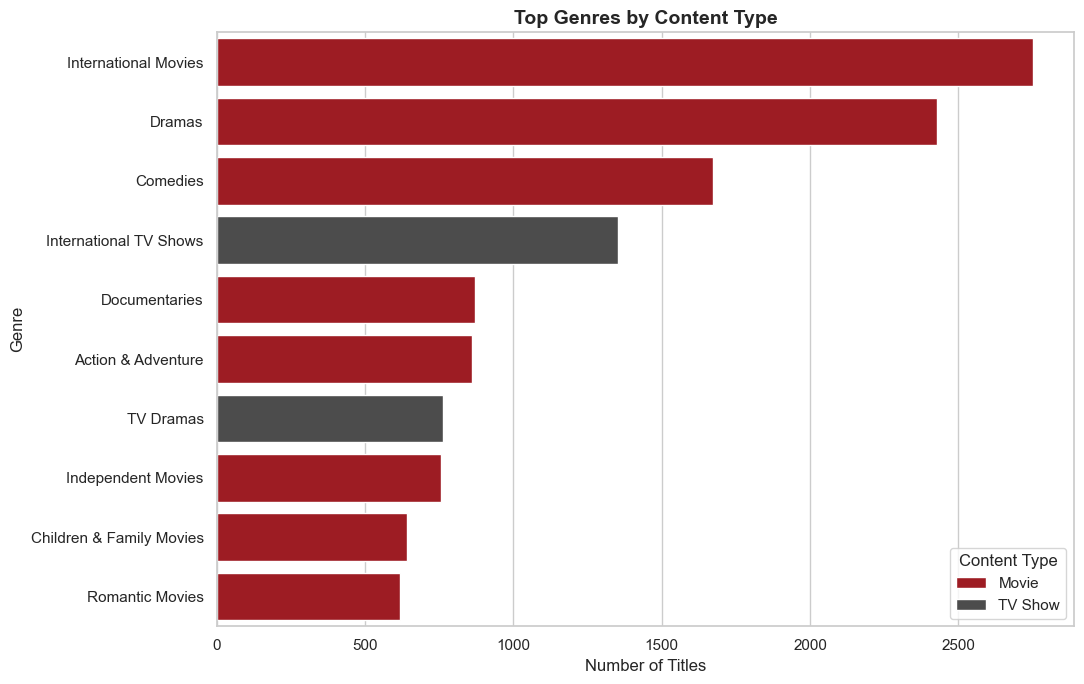

In [32]:
top10_names = top_genres.index.tolist()
genre_type = (genre_df[genre_df["genre"].isin(top10_names)]
              .groupby(["genre", "type"]).size().reset_index(name="titles"))

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=genre_type, y="genre", x="titles", hue="type",
            order=top10_names, palette=TYPE_PALETTE, ax=ax)
ax.set_title("Top Genres by Content Type", fontsize=14)
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Genre")
ax.legend(title="Content Type")
save_chart(fig, "08_genres_by_content_type.png")
plt.show()

*Note:* some genres exist for only one type (e.g. "International Movies" applies to movies; "International TV Shows" to TV). Only genres in the overall Top 10 are shown to avoid clutter.

## 19. Optional Visualization — Monthly Content Addition

Valid date_added values: 8,797 (99.9%) -> enough for a monthly view
Saved: E:/HorizonX/task4/visualisations\09_monthly_content_additions.png


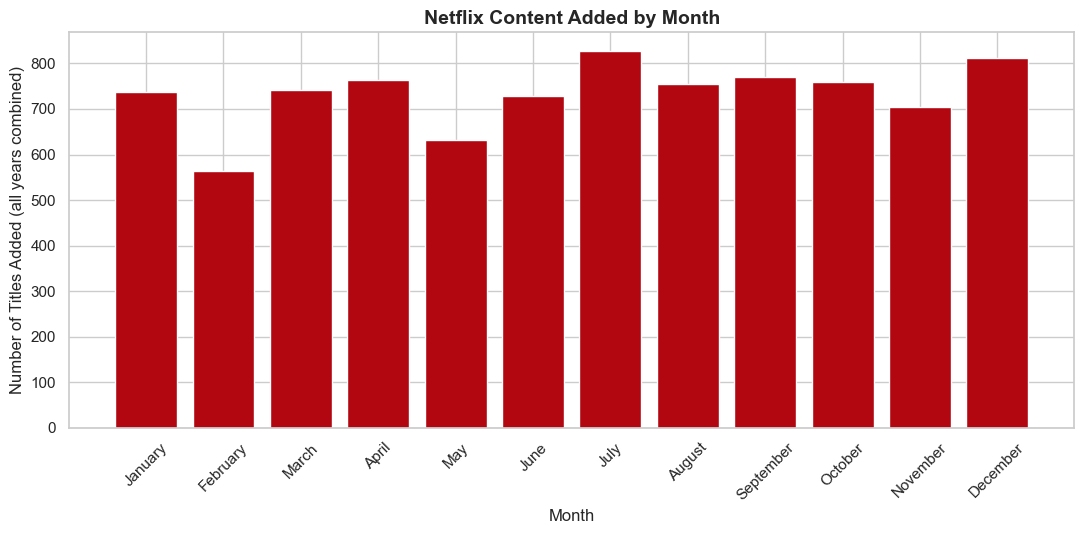

In [33]:
valid_dates = df["date_added"].notna().sum()
print(f"Valid date_added values: {valid_dates:,} ({valid_dates / len(df) * 100:.1f}%) -> enough for a monthly view")

month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
monthly = df["month_name"].value_counts().reindex(month_order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(monthly.index, monthly.values, color=NETFLIX_RED)
ax.set_title("Netflix Content Added by Month", fontsize=14)
ax.set_xlabel("Month")
ax.set_ylabel("Number of Titles Added (all years combined)")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "09_monthly_content_additions.png")
plt.show()

## 20. Correlation Analysis
Most columns are categorical, so correlation is not meaningful for them. The only numeric fields are `release_year`, `year_added` and `duration_value`. `duration_value` mixes **minutes** (movies) and **seasons** (TV shows), so it is only valid **for movies**. We therefore compute the matrix on movies only.

,release_year,year_added,duration_value
release_year,1.00,0.04,-0.21
year_added,0.04,1.00,0.13
duration_value,-0.21,0.13,1.00


Saved: E:/HorizonX/task4/visualisations\10_correlation_heatmap.png


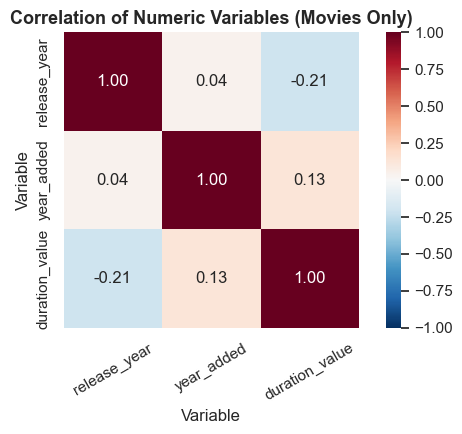

In [34]:
corr_data = movies[movies["duration_unit"] == "Minutes"][["release_year", "year_added", "duration_value"]].dropna().astype(float)
corr = corr_data.corr()
display(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation of Numeric Variables (Movies Only)", fontsize=13)
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
ax.tick_params(axis="x", rotation=30)
save_chart(fig, "10_correlation_heatmap.png")
plt.show()

**Interpretation:** `release_year` and `year_added` show a positive relationship, which is expected because a title cannot be added before it is released. Duration shows only weak relationships with the other variables. Correlation here is descriptive and does not imply causation.

## 21. Save Processed Data

In [35]:
processed_path = os.path.join(PROCESSED_DIR, "netflix_processed.csv")
genres_path = os.path.join(PROCESSED_DIR, "netflix_genres.csv")
countries_path = os.path.join(PROCESSED_DIR, "netflix_countries.csv")

# Keep the date as plain YYYY-MM-DD for easy Power BI import
export_df = df.copy()
export_df["date_added"] = export_df["date_added"].dt.strftime("%Y-%m-%d")

export_df.to_csv(processed_path, index=False)
genre_df.to_csv(genres_path, index=False)
country_df.to_csv(countries_path, index=False)

for p in [processed_path, genres_path, countries_path]:
    print(f"{p}  ({os.path.getsize(p) / 1024:,.0f} KB)")

E:/HorizonX/task4/processed\netflix_processed.csv  (3,727 KB)
E:/HorizonX/task4/processed\netflix_genres.csv  (879 KB)
E:/HorizonX/task4/processed\netflix_countries.csv  (448 KB)


## 22. Final Data Validation

In [37]:
check = pd.read_csv(processed_path)   # re-read the saved file to verify it

print("Processed file exists:", os.path.exists(processed_path))
print("Final shape:", check.shape)
print("Duplicate rows:", check.duplicated().sum())
print("\nMissing values (remaining are only missing date_added values and the date features derived from them):")
print(check.isna().sum()[check.isna().sum() > 0])
print("\nData types:")
print(check.dtypes)
display(check.head())

Processed file exists: True
Final shape: (8807, 19)
Duplicate rows: 0

Missing values (remaining are only missing date_added values and the date features derived from them):
date_added     10
year_added     10
month_added    10
month_name     10
dtype: int64

Data types:
show_id             object
type                object
title               object
director            object
cast                object
country             object
date_added          object
release_year         int64
rating              object
duration            object
listed_in           object
description         object
year_added         float64
month_added        float64
month_name          object
duration_value       int64
duration_unit       object
primary_genre       object
country_primary     object
dtype: object


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,month_name,duration_value,duration_unit,primary_genre,country_primary
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0,September,90,Minutes,Documentaries,United States
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0,September,2,Season,International TV Shows,South Africa
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0,September,1,Season,Crime TV Shows,Unknown
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0,September,1,Season,Docuseries,Unknown
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0,September,2,Season,International TV Shows,India


# Key Insights

In [38]:
top_type = type_counts.idxmax()
top_country = top_countries.idxmax()
top_genre = top_genres.idxmax()
top_rating = df["rating"].value_counts().idxmax()
peak_year = int(added_per_year.idxmax())
peak_month = monthly.idxmax()

insights = [
    f"The dataset shows {top_type}s are the larger category: {type_counts[top_type]:,} titles ({type_share[top_type]}% of the catalogue).",
    f"{top_country} has the most titles with a listed country ({top_countries[top_country]:,}); {df['country'].eq('Unknown').sum():,} titles have no country recorded.",
    f"The most common genre label is {top_genre} ({top_genres[top_genre]:,} titles), counting every genre listed per title.",
    f"The most common rating is {top_rating} ({df['rating'].value_counts().iloc[0]:,} titles).",
    f"The most titles were added in {peak_year} ({added_per_year[peak_year]:,} titles); the dataset snapshot ends on {df['date_added'].max().date()}.",
    f"{peak_month} has the highest number of additions when all years are combined ({monthly[peak_month]:,} titles).",
    f"Movies average {movie_minutes.mean():.0f} minutes (median {movie_minutes.median():.0f}, range {movie_minutes.min():.0f}-{movie_minutes.max():.0f}).",
    f"Release years run from {kpis['Earliest release year']} to {kpis['Latest release year']}, and {recent_share:.0f}% of titles were released in 2015 or later, so the catalogue skews recent.",
]
for i, text in enumerate(insights, 1):
    print(f"{i}. {text}")

1. The dataset shows Movies are the larger category: 6,131 titles (69.6% of the catalogue).
2. United States has the most titles with a listed country (3,690); 831 titles have no country recorded.
3. The most common genre label is International Movies (2,752 titles), counting every genre listed per title.
4. The most common rating is TV-MA (3,207 titles).
5. The most titles were added in 2019 (2,016 titles); the dataset snapshot ends on 2021-09-25.
6. July has the highest number of additions when all years are combined (827 titles).
7. Movies average 100 minutes (median 98, range 3-312).
8. Release years run from 1925 to 2021, and 71% of titles were released in 2015 or later, so the catalogue skews recent.


## 24. Visualization Summary Table

In [39]:
viz_summary = pd.DataFrame({
    "Visualization": ["Movies vs TV Shows", "Content Added Over Time", "Top Countries", "Top Genres",
                      "Ratings", "Release Years", "Movie Duration", "Genres by Type"],
    "Purpose": ["Content type comparison", "Trend analysis", "Geographic distribution", "Genre distribution",
                "Rating distribution", "Release pattern", "Duration distribution", "Movie vs TV genre comparison"],
    "File": ["01_movies_vs_tv_shows.png", "02_content_added_over_time.png", "03_top_10_countries.png",
             "04_top_10_genres.png", "05_content_ratings.png", "06_release_year_distribution.png",
             "07_movie_duration_distribution.png", "08_genres_by_content_type.png"],
})
viz_summary["Saved"] = viz_summary["File"].apply(lambda f: os.path.exists(os.path.join(CHART_DIR, f)))
display(viz_summary)

,Visualization,Purpose,File,Saved
0,Movies vs TV Shows,Content type comparison,01_movies_vs_tv_shows.png,True
1,Content Added Over Time,Trend analysis,02_content_added_over_time.png,True
2,Top Countries,Geographic distribution,03_top_10_countries.png,True
3,Top Genres,Genre distribution,04_top_10_genres.png,True
4,Ratings,Rating distribution,05_content_ratings.png,True
5,Release Years,Release pattern,06_release_year_distribution.png,True
6,Movie Duration,Duration distribution,07_movie_duration_distribution.png,True
7,Genres by Type,Movie vs TV genre comparison,08_genres_by_content_type.png,True


# Next Step — Power BI Dashboard

The generated files can now be imported into Power BI (**Get Data → Text/CSV**):

- `../processed_data/netflix_processed.csv` — main table (one row per title)
- `../processed_data/netflix_genres.csv` — one row per title–genre (for genre visuals)
- `../processed_data/netflix_countries.csv` — one row per title–country (for country visuals)

Relate the helper tables to the main table using `show_id`.

**Recommended dashboard components**
- KPI cards (total titles, movies, TV shows, countries, genres)
- Movies vs TV Shows
- Content Added Over Time
- Top Countries
- Top Genres
- Ratings
- Release Year Distribution
- Genre vs Content Type
- Slicers for **Type**, **Rating**, **Country** and **Year**